<a href="https://colab.research.google.com/github/jayhaming10936-eng/Bengil_Tyron_DecisionTree_Activity.ipynb/blob/main/Bengil_Tyron_DecisionTree_Activity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TYRON BENGIL


## II. Baseline Experiments (Diagrams 1–9)
Run each cell without changing the baseline parameters. Later, complete all five challenges in **IV. Student Exercises and Wrap-up**. Keep the baseline outputs for comparison.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, mean_squared_error)

RANDOM_STATE = 42
BASELINE_NOISE = 0.22
BASELINE_DEPTH = 3
BASELINE_LEAF = 1
BASELINE_REG_DEPTH = 4
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': False})
print('Ready. All datasets in this notebook are synthetic and reproducible.')

Ready. All datasets in this notebook are synthetic and reproducible.


In [2]:
def classification_data(noise=BASELINE_NOISE):
    X, y = make_moons(n_samples=450, noise=noise, random_state=RANDOM_STATE)
    return train_test_split(X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y)

def classification_model(X_train, y_train, depth=BASELINE_DEPTH, leaf=BASELINE_LEAF):
    return DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf,
                                  criterion='gini', random_state=RANDOM_STATE).fit(X_train, y_train)

def classification_scores(model, X_train, X_test, y_train, y_test):
    return {'train_accuracy': accuracy_score(y_train, model.predict(X_train)),
            'test_accuracy': accuracy_score(y_test, model.predict(X_test)),
            'nodes': model.tree_.node_count,
            'leaves': model.get_n_leaves()}

def draw_boundary(model, X, y, title, ax=None):
    if ax is None: _, ax = plt.subplots(figsize=(6, 4))
    x0, x1 = X[:, 0], X[:, 1]
    xx, yy = np.meshgrid(np.linspace(x0.min()-.5, x0.max()+.5, 230),
                         np.linspace(x1.min()-.5, x1.max()+.5, 230))
    zz = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.23, cmap='coolwarm')
    ax.scatter(x0, x1, c=y, s=13, cmap='coolwarm', edgecolors='none', alpha=.75)
    ax.set(title=title, xlabel='Feature 1', ylabel='Feature 2')
    return ax

def regression_data():
    rng = np.random.default_rng(RANDOM_STATE)
    x = np.sort(6 * rng.random(220))
    y = np.sin(1.5*x) + .25*np.cos(3*x) + rng.normal(0, .23, size=x.shape)
    X = x.reshape(-1, 1)
    return train_test_split(X, y, test_size=.30, random_state=RANDOM_STATE)

def regression_model(X_train, y_train, depth=BASELINE_REG_DEPTH):
    return DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE).fit(X_train, y_train)

def regression_rmse(model, X, y):
    return np.sqrt(mean_squared_error(y, model.predict(X)))

def draw_regression_curve(model, X_train, y_train, X_test, y_test, title, ax=None):
    if ax is None: _, ax = plt.subplots(figsize=(7, 4))
    xx = np.linspace(0, 6, 600).reshape(-1, 1)
    ax.scatter(X_train[:,0], y_train, s=17, alpha=.53, label='Training samples')
    ax.scatter(X_test[:,0], y_test, s=18, alpha=.64, label='Test samples', marker='x')
    ax.plot(xx[:,0], model.predict(xx), color='black', linewidth=2, label='Tree prediction')
    ax.set(title=title, xlabel='Input feature', ylabel='Target')
    ax.legend(fontsize=8)
    return ax

X_train, X_test, y_train, y_test = classification_data()
classifier = classification_model(X_train, y_train)
Xr_train, Xr_test, yr_train, yr_test = regression_data()
regressor = regression_model(Xr_train, yr_train)
print('Classification split:', len(X_train), 'training /', len(X_test), 'test samples')
print('Regression split:', len(Xr_train), 'training /', len(Xr_test), 'test samples')

Classification split: 315 training / 135 test samples
Regression split: 154 training / 66 test samples


### Diagram 1 — Classification Dataset
Synthetic interleaving-moons data. Notice that the two classes overlap, so some errors are expected.

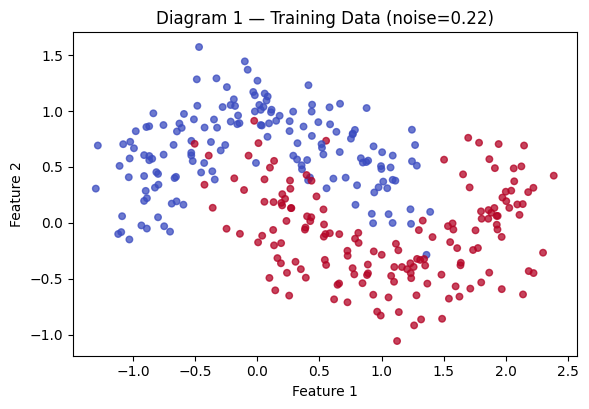

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(X_train[:,0], X_train[:,1], c=y_train, cmap='coolwarm', s=22, alpha=.75)
ax.set(title=f'Diagram 1 — Training Data (noise={BASELINE_NOISE})', xlabel='Feature 1', ylabel='Feature 2')
plt.show()

### Diagram 2 — Classification Tree Structure
Each split uses a feature threshold. A terminal node (leaf) outputs a class. Tree structures can become too large to display fully; `plot_tree` is limited to its first three levels for readability.

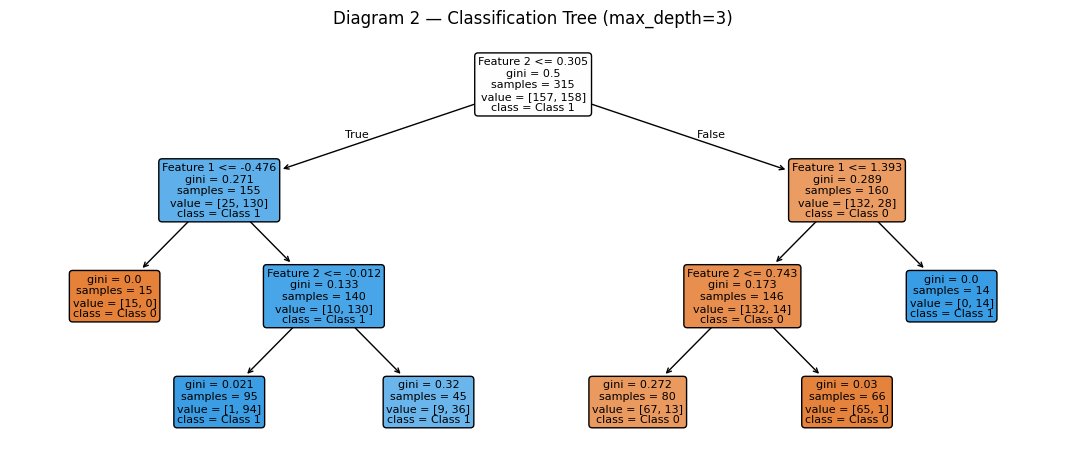

Baseline classification: {'train_accuracy': 0.9238095238095239, 'test_accuracy': 0.9037037037037037, 'nodes': 11, 'leaves': np.int64(6)}


In [4]:
fig, ax = plt.subplots(figsize=(13.5, 5.5))
plot_tree(classifier, max_depth=3, filled=True, rounded=True, fontsize=8,
          feature_names=['Feature 1','Feature 2'], class_names=['Class 0','Class 1'], ax=ax)
ax.set_title(f'Diagram 2 — Classification Tree (max_depth={BASELINE_DEPTH})')
plt.show()
print('Baseline classification:', classification_scores(classifier, X_train, X_test, y_train, y_test))

### Diagram 3 — Classification Decision Boundary
Decision trees produce axis-aligned, rectangular partition boundaries for these two numerical features.

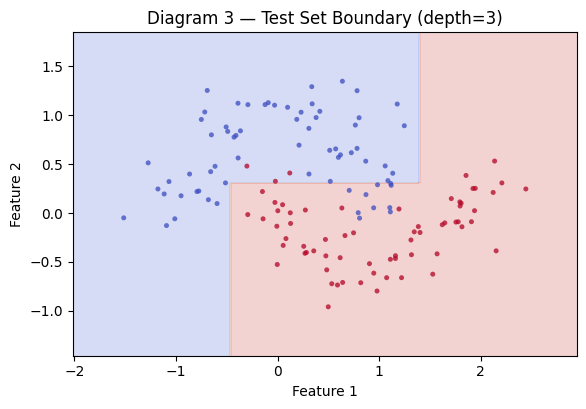

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
draw_boundary(classifier, X_test, y_test, f'Diagram 3 — Test Set Boundary (depth={BASELINE_DEPTH})', ax=ax)
plt.show()

### Diagram 4 — Model Complexity: Train vs. Test Accuracy
Depth is varied while the **same data split** is held fixed. The highest training accuracy is not necessarily the highest test accuracy.

,max_depth,train_accuracy,test_accuracy,leaves
0,1,0.832,0.807,2
1,2,0.924,0.904,4
2,3,0.924,0.904,6
3,4,0.930,0.904,10
4,5,0.946,0.911,15
5,6,0.978,0.963,18
6,7,0.984,0.956,22
7,8,0.994,0.956,25
8,9,0.997,0.956,27
9,10,1.000,0.948,28


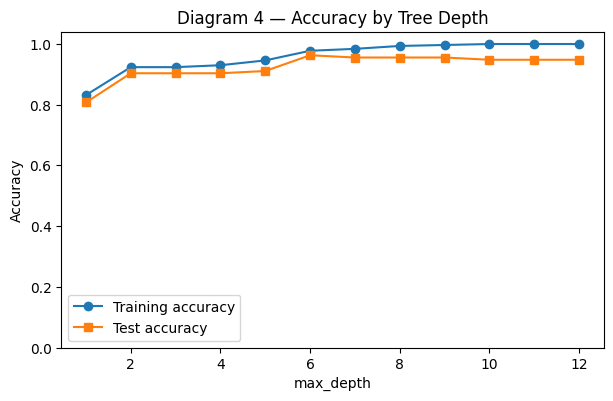

In [6]:
depth_results=[]
for depth in range(1, 13):
    m=classification_model(X_train, y_train, depth=depth)
    r=classification_scores(m, X_train, X_test, y_train, y_test)
    depth_results.append({'max_depth': depth, **r})
depth_df=pd.DataFrame(depth_results)
display(depth_df[['max_depth','train_accuracy','test_accuracy','leaves']].round(3))
fig, ax=plt.subplots(figsize=(7,4.1))
ax.plot(depth_df.max_depth, depth_df.train_accuracy, 'o-', label='Training accuracy')
ax.plot(depth_df.max_depth, depth_df.test_accuracy, 's-', label='Test accuracy')
ax.set(title='Diagram 4 — Accuracy by Tree Depth', xlabel='max_depth', ylabel='Accuracy', ylim=(0,1.04))
ax.legend(); plt.show()

### Diagram 5 — Feature Importance
Importance describes the total weighted reduction in split criterion attributable to each feature; it does **not** prove causality.

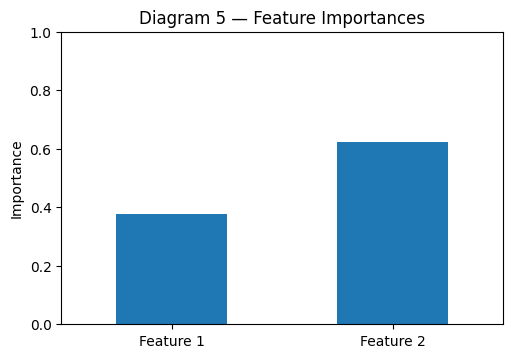

Feature 1    0.377
Feature 2    0.623


In [7]:
importance=pd.Series(classifier.feature_importances_, index=['Feature 1','Feature 2'])
fig, ax=plt.subplots(figsize=(5.7,3.8))
importance.plot(kind='bar', ax=ax)
ax.set(title='Diagram 5 — Feature Importances', ylabel='Importance', ylim=(0,1))
plt.xticks(rotation=0); plt.show()
print(importance.round(3).to_string())

### Diagram 6 — Classification Confusion Matrix
**Rows are true classes; columns are predicted classes.** For class 1 as the positive class, an off-diagonal top-right cell is a false positive; the bottom-left cell is a false negative.

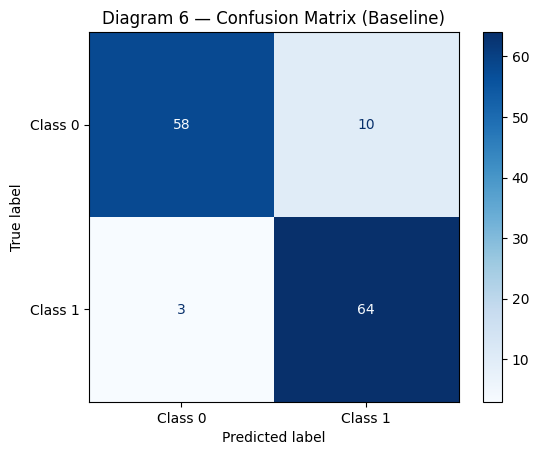

              precision    recall  f1-score   support

           0       0.95      0.85      0.90        68
           1       0.86      0.96      0.91        67

    accuracy                           0.90       135
   macro avg       0.91      0.90      0.90       135
weighted avg       0.91      0.90      0.90       135



In [8]:
yp=classifier.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, yp, display_labels=['Class 0','Class 1'], cmap='Blues', values_format='d')
plt.title('Diagram 6 — Confusion Matrix (Baseline)'); plt.show()
print(classification_report(y_test, yp, zero_division=0))

### Diagram 7 — Regression Dataset
The regression target is a continuous value. The training samples include noise.

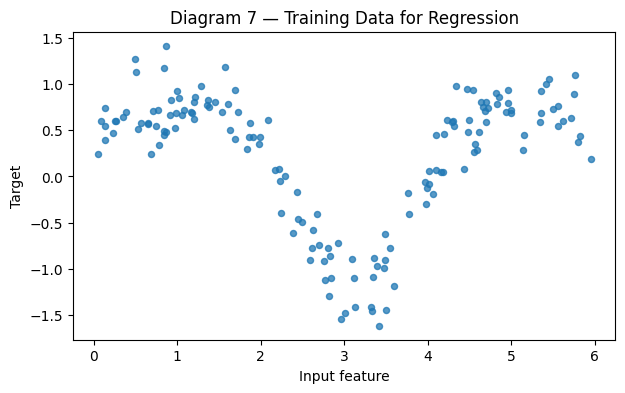

In [9]:
fig, ax=plt.subplots(figsize=(7,4))
ax.scatter(Xr_train[:,0], yr_train, s=19, alpha=.75)
ax.set(title='Diagram 7 — Training Data for Regression', xlabel='Input feature', ylabel='Target')
plt.show()

### Diagram 8 — Regression Tree Structure
Regression leaves predict averages of the training targets within each terminal region.

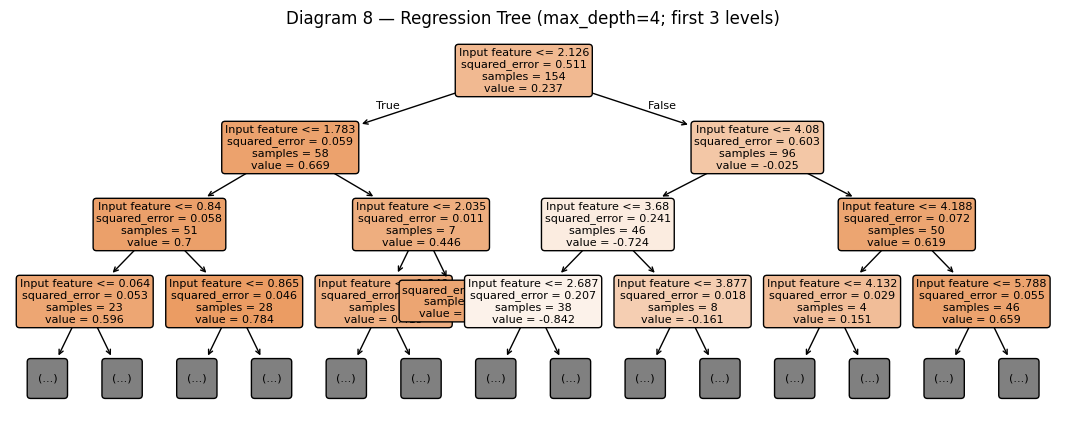

In [10]:
fig, ax=plt.subplots(figsize=(13.5,5))
plot_tree(regressor, max_depth=3, filled=True, rounded=True, fontsize=8, feature_names=['Input feature'], ax=ax)
ax.set_title(f'Diagram 8 — Regression Tree (max_depth={BASELINE_REG_DEPTH}; first 3 levels)')
plt.show()

### Diagram 9 — Regression Prediction Curve
A decision-tree regressor predicts a piecewise-constant (step-shaped) function. Evaluate prediction quality using **test RMSE**, not apparent smoothness.

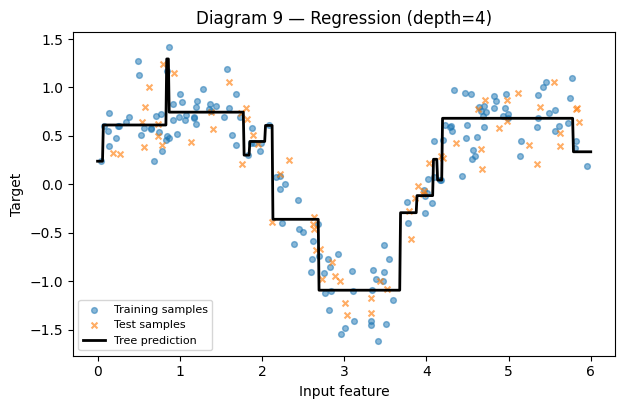

Baseline train RMSE: 0.221
Baseline test RMSE: 0.28


In [11]:
fig, ax=plt.subplots(figsize=(7,4.2))
draw_regression_curve(regressor, Xr_train, yr_train, Xr_test, yr_test,
                      f'Diagram 9 — Regression (depth={BASELINE_REG_DEPTH})', ax=ax)
plt.show()
print('Baseline train RMSE:', round(regression_rmse(regressor, Xr_train, yr_train),3))
print('Baseline test RMSE:', round(regression_rmse(regressor, Xr_test, yr_test),3))

## III. Student Exercises and Wrap-up
**Complete all five challenges.** In each exercise cell, change only the indicated value or list, rerun it, capture the resulting figure(s) and metrics, and write **3–5 sentences** explaining what you changed, what you observed, why the algorithm behaved that way, and what the experiment shows.

Before making changes, save the original baseline outputs. Do not claim that deeper trees or higher accuracy on the training set automatically mean better generalization.

### Challenge 1 — Tree Depth and Structure (Diagrams 2–3)
**Required modification:** Replace the default `depths = [3]` with **`[1, 3, 8]`**. Compare tree diagrams, nodes, leaves, decision boundaries, and training/test accuracy. The diagram truncates the displayed tree at three levels; the depth-8 model itself is **not** truncated.

**Interpretation (3–5 sentences):** What changed about the partitions and model complexity? Which depth generalized best on the test data?

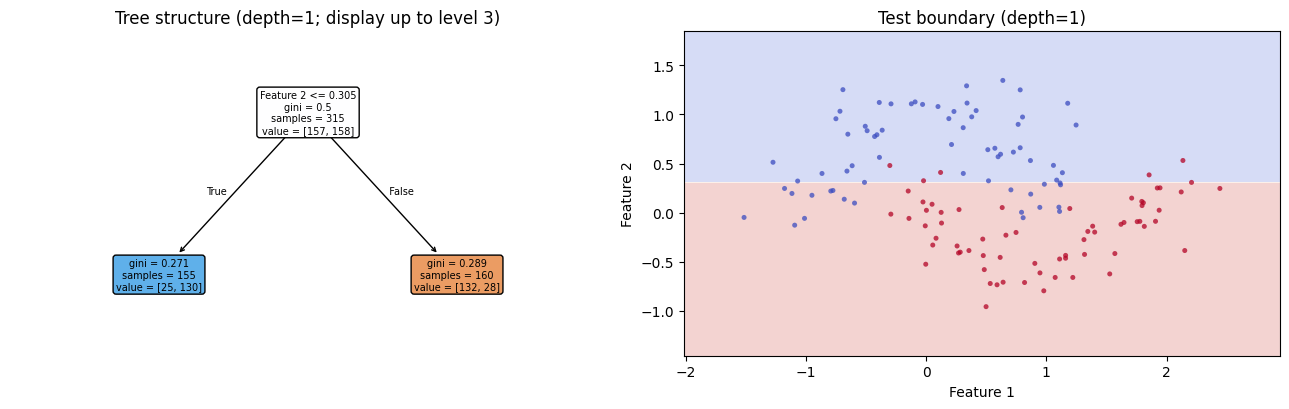

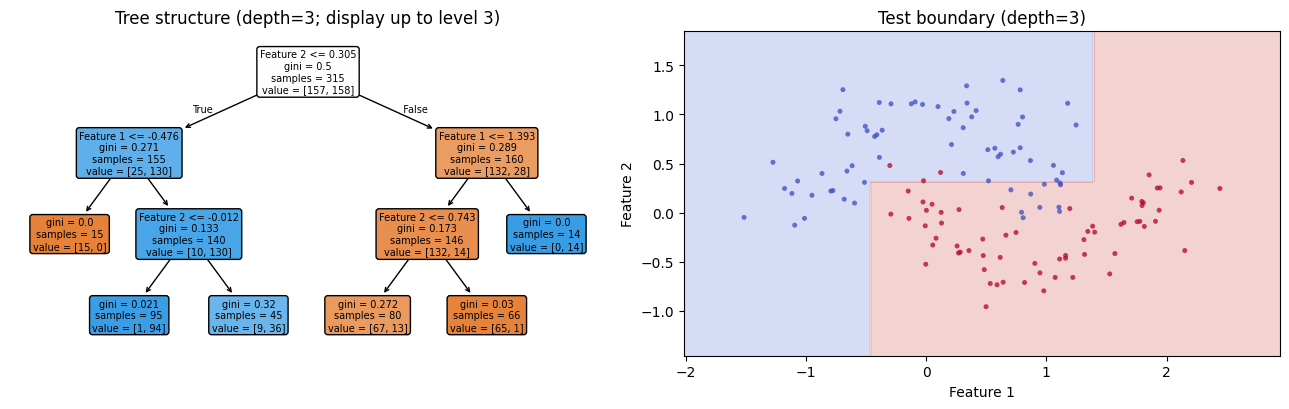

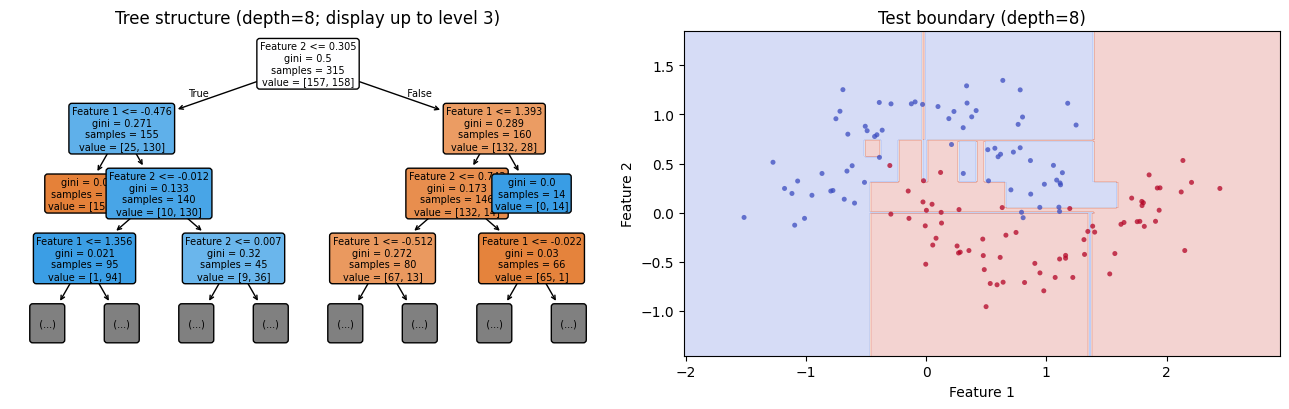

,depth,train_accuracy,test_accuracy,nodes,leaves
0,1,0.832,0.807,3,2
1,3,0.924,0.904,11,6
2,8,0.994,0.956,49,25


In [12]:
# CHALLENGE 1 — STUDENT MODIFICATION
# DONE: changed [3] to [1, 3, 8]
depths = [1, 3, 8]
results=[]
for d in depths:
    m=classification_model(X_train, y_train, depth=d)
    r=classification_scores(m, X_train, X_test, y_train, y_test)
    results.append({'depth':d, **r})
    fig, axes=plt.subplots(1,2,figsize=(13,4.2))
    plot_tree(m, max_depth=3, filled=True, rounded=True, fontsize=7,
              feature_names=['Feature 1','Feature 2'], ax=axes[0])
    axes[0].set_title(f'Tree structure (depth={d}; display up to level 3)')
    draw_boundary(m, X_test, y_test, f'Test boundary (depth={d})', axes[1])
    plt.tight_layout(); plt.show()
display(pd.DataFrame(results).round(3))

**Interpretation — Challenge 1.** I changed `depths` from `[3]` to `[1, 3, 8]`. At depth 1 the tree makes a single split (3 nodes, 2 leaves), so the boundary is one straight axis-aligned line and the model underfits (train 0.832, test 0.807). Depth 3 gives 11 nodes and 6 leaves and lifts test accuracy to 0.904, while depth 8 grows to 49 nodes and 25 leaves, cutting the plane into many small rectangles that follow the curved moons. Depth 8 generalized best of the three (train 0.994, test 0.956), but its 3.8-point train-test gap shows it is starting to fit noise, and the plotted tree only shows 3 levels even though the fitted model uses all 8.

### Challenge 2 — Minimum Samples per Leaf (Diagram 3)
**Required modification:** Replace `leaf_values = [1]` with **`[1, 5, 15]`**. Keep `max_depth=8`, the split, and noise fixed. Compare decision boundaries, complexity, and training/test accuracy.

**Interpretation (3–5 sentences):** How does restricting leaf size change the fitted regions? Does reducing complexity improve test performance for these data?

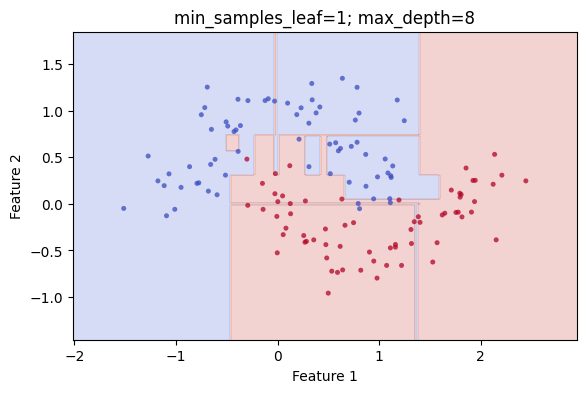

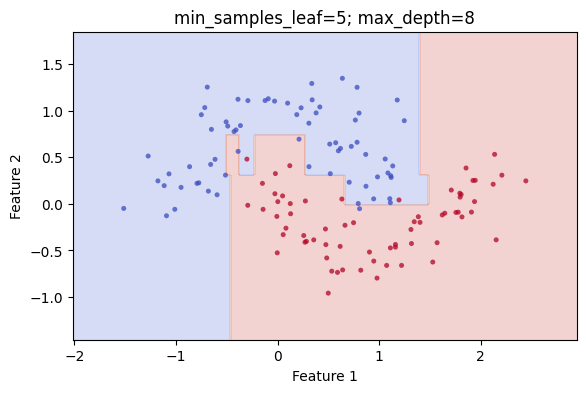

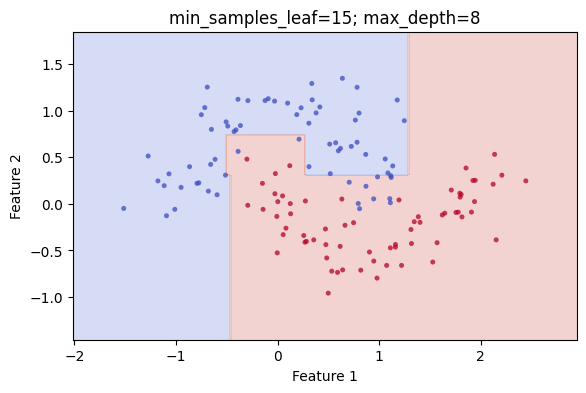

,min_samples_leaf,train_accuracy,test_accuracy,nodes,leaves
0,1,0.994,0.956,49,25
1,5,0.971,0.963,37,19
2,15,0.927,0.911,25,13


In [13]:
# CHALLENGE 2 — STUDENT MODIFICATION
# DONE: changed [1] to [1, 5, 15]
leaf_values = [1, 5, 15]
results=[]
for leaf in leaf_values:
    m=classification_model(X_train, y_train, depth=8, leaf=leaf)
    r=classification_scores(m, X_train, X_test, y_train, y_test)
    results.append({'min_samples_leaf':leaf, **r})
    fig, ax=plt.subplots(figsize=(6.5,4))
    draw_boundary(m, X_test, y_test, f'min_samples_leaf={leaf}; max_depth=8', ax)
    plt.show()
display(pd.DataFrame(results).round(3))

**Interpretation — Challenge 2.** I changed `leaf_values` from `[1]` to `[1, 5, 15]` with `max_depth=8` fixed. Requiring more samples per leaf removes tiny isolated regions: leaves drop from 25 to 19 to 13 and nodes from 49 to 37 to 25, so the boundary becomes smoother. `min_samples_leaf=5` reduced the train-test gap (0.971 vs 0.963) and gave the best test accuracy of the three (0.963), while `min_samples_leaf=15` over-restricted the tree and fell to 0.911 on test (underfitting). So moderate pruning helped slightly, but the 0.956 to 0.963 gain is only one test sample out of 135, so I treat it as 'about equal' rather than a clear win.

### Challenge 3 — Dataset Variability (Diagrams 1, 3, and 6)
**Required modification:** Change `modified_noise = 0.22` to **`0.38`**. Compare with Diagram 1 and the original baseline results. Recreate the dataset **and retrain**; old models must not be applied to a newly generated dataset when making this comparison. Report test accuracy and show the updated scatter plot and boundary.

**Interpretation (3–5 sentences):** How does overlap affect the tree's decisions and errors? Is the observed performance difference supported by test results?

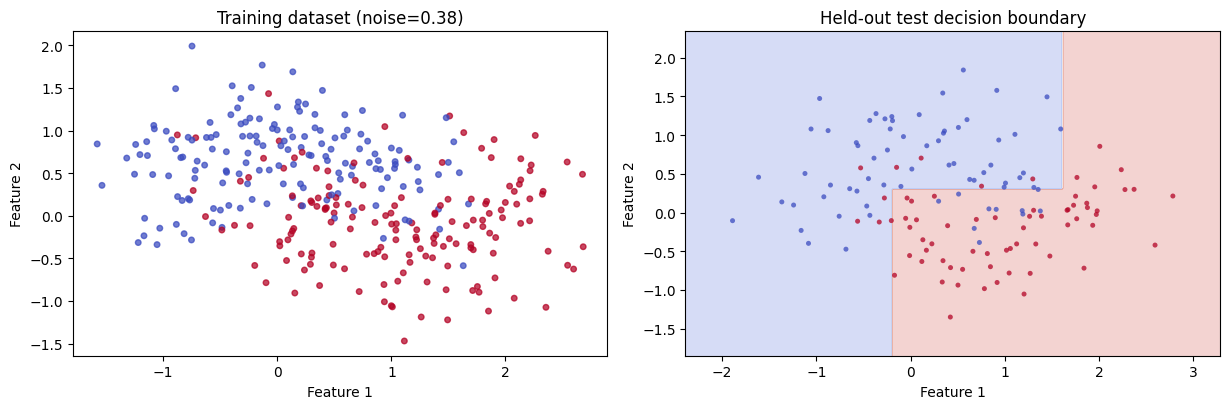

Baseline noise: 0.22 | modified noise: 0.38
New-data scores: {'train_accuracy': 0.8698412698412699, 'test_accuracy': 0.8666666666666667, 'nodes': 13, 'leaves': np.int64(7)}


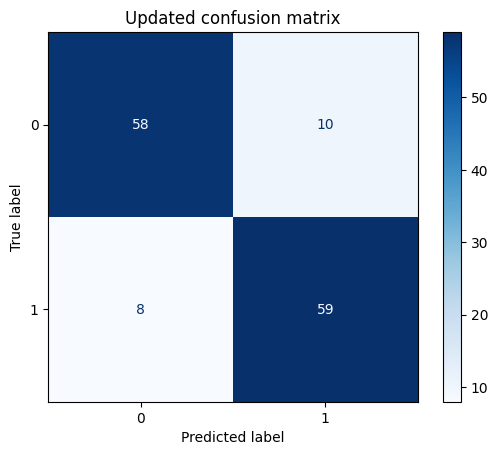

In [14]:
# CHALLENGE 3 — STUDENT MODIFICATION
# DONE: changed modified_noise from 0.22 to 0.38
modified_noise = 0.38
Xa, Xb, ya, yb = classification_data(noise=modified_noise)
changed=classification_model(Xa, ya, depth=BASELINE_DEPTH)
fig, axes=plt.subplots(1,2,figsize=(12.4,4.2))
axes[0].scatter(Xa[:,0], Xa[:,1], c=ya, cmap='coolwarm', s=16, alpha=.73)
axes[0].set(title=f'Training dataset (noise={modified_noise})', xlabel='Feature 1', ylabel='Feature 2')
draw_boundary(changed, Xb, yb, 'Held-out test decision boundary', axes[1])
plt.tight_layout(); plt.show()
print('Baseline noise:', BASELINE_NOISE, '| modified noise:', modified_noise)
print('New-data scores:', classification_scores(changed, Xa, Xb, ya, yb))
ConfusionMatrixDisplay.from_predictions(yb, changed.predict(Xb), cmap='Blues', values_format='d')
plt.title('Updated confusion matrix'); plt.show()

**Interpretation — Challenge 3.** I changed `modified_noise` from 0.22 to 0.38 and retrained on the newly generated data. More noise makes the two moons overlap, so no axis-aligned rectangle can separate them cleanly: training accuracy fell from 0.924 to 0.870 and test accuracy from 0.904 to 0.867. In the confusion matrices the false positives for class 1 stayed at 10, while false negatives rose from 3 to 8, so the extra errors came from class 1 points landing in class 0 territory. The drop is supported by held-out results, though with 135 test samples a 3.7-point difference is suggestive rather than conclusive.

### Challenge 4 — Confusion Matrix Analysis (Diagram 6)
**Required modification:** Replace `matrix_depths = [3]` with **`[2, 8]`**. Train and evaluate each model on the **same original split**. Identify the number of true positives, true negatives, false positives, and false negatives for class 1; also compare precision, recall, and test accuracy.

**Interpretation (3–5 sentences):** Which error types changed? Which depth would you select based on held-out performance, and why?

Depth 2: TN=58, FP=10, FN=3, TP=64; test accuracy=0.904
              precision    recall  f1-score   support

           0       0.95      0.85      0.90        68
           1       0.86      0.96      0.91        67

    accuracy                           0.90       135
   macro avg       0.91      0.90      0.90       135
weighted avg       0.91      0.90      0.90       135



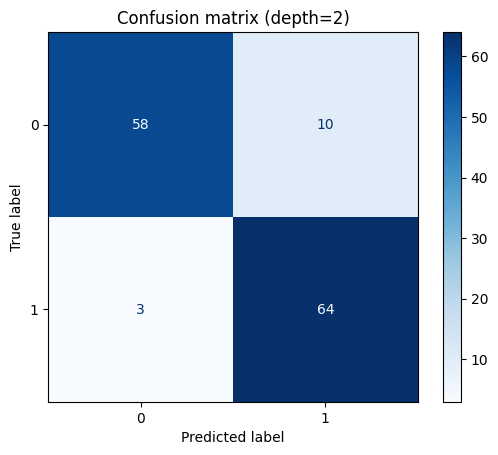

Depth 8: TN=65, FP=3, FN=3, TP=64; test accuracy=0.956
              precision    recall  f1-score   support

           0       0.96      0.96      0.96        68
           1       0.96      0.96      0.96        67

    accuracy                           0.96       135
   macro avg       0.96      0.96      0.96       135
weighted avg       0.96      0.96      0.96       135



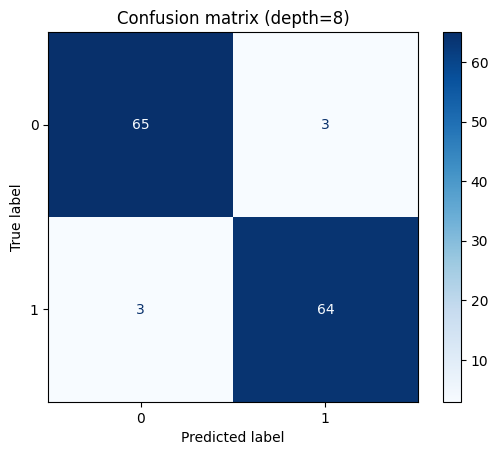

In [15]:
# CHALLENGE 4 — STUDENT MODIFICATION
# DONE: changed [3] to [2, 8]
matrix_depths = [2, 8]
for d in matrix_depths:
    m=classification_model(X_train, y_train, depth=d)
    p=m.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, p, labels=[0,1]).ravel()
    print(f'Depth {d}: TN={tn}, FP={fp}, FN={fn}, TP={tp}; test accuracy={accuracy_score(y_test,p):.3f}')
    print(classification_report(y_test,p,zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test,p,labels=[0,1],cmap='Blues',values_format='d')
    plt.title(f'Confusion matrix (depth={d})'); plt.show()

**Interpretation — Challenge 4.** I changed `matrix_depths` from `[3]` to `[2, 8]` on the same split. At depth 2 the counts for class 1 were TN=58, FP=10, FN=3, TP=64 (precision 0.86, recall 0.96, accuracy 0.904); at depth 8 they were TN=65, FP=3, FN=3, TP=64 (precision 0.96, recall 0.96, accuracy 0.956). The false negatives did not change; the improvement came entirely from false positives falling from 10 to 3, which raised precision. I would select depth 8 of these two because it is clearly better on held-out data, although the depth sweep in Diagram 4 shows depths 6 to 9 perform similarly, so I would not claim depth 8 is uniquely optimal.

### Challenge 5 — Decision Tree Regression (Diagram 9)
**Required modification:** Replace `regression_depths = [4]` with **`[2, 4, 10]`**. Compare the three prediction curves, number of leaves, training RMSE, and held-out test RMSE.

**Interpretation (3–5 sentences):** Which curve is most complex? Does the lowest training error achieve the lowest test error? Explain the stepwise behavior.

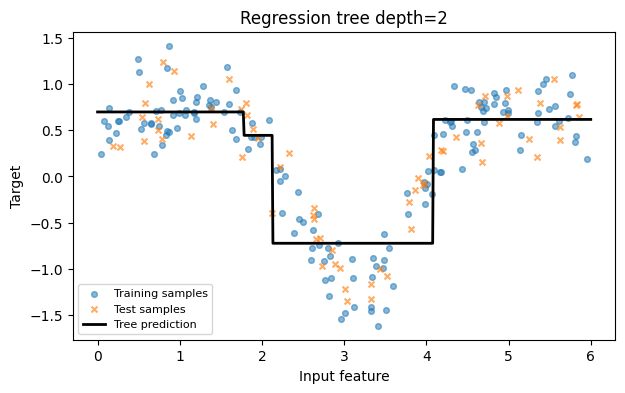

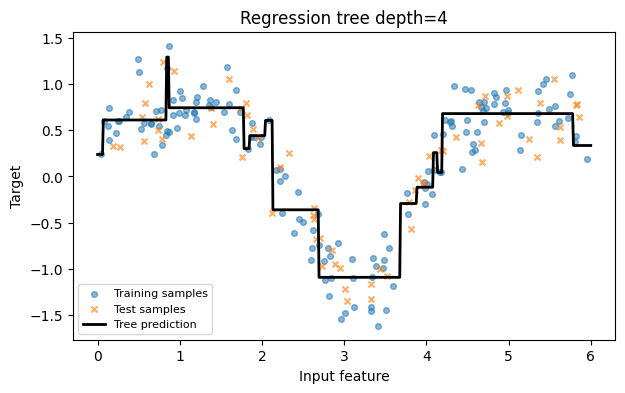

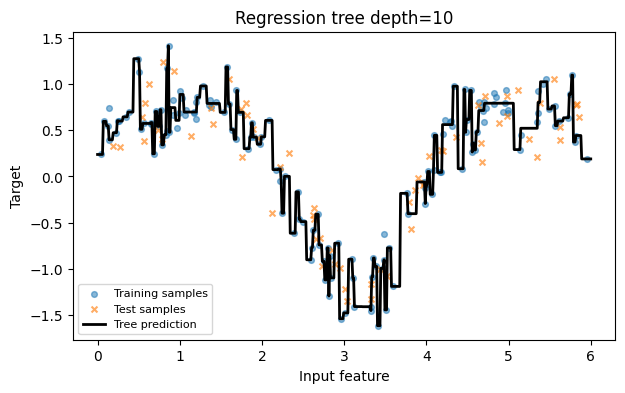

,depth,leaves,train_rmse,test_rmse
0,2,4,0.339,0.380
1,4,15,0.221,0.280
2,10,123,0.036,0.296


In [16]:
# CHALLENGE 5 — STUDENT MODIFICATION
# DONE: changed [4] to [2, 4, 10]
regression_depths = [2, 4, 10]
results=[]
for d in regression_depths:
    m=regression_model(Xr_train, yr_train, depth=d)
    results.append({'depth': d, 'leaves': m.get_n_leaves(),
                    'train_rmse': regression_rmse(m, Xr_train, yr_train),
                    'test_rmse': regression_rmse(m, Xr_test, yr_test)})
    fig, ax=plt.subplots(figsize=(7,4))
    draw_regression_curve(m, Xr_train, yr_train, Xr_test, yr_test, f'Regression tree depth={d}', ax)
    plt.show()
display(pd.DataFrame(results).round(3))

**Interpretation — Challenge 5.** I changed `regression_depths` from `[4]` to `[2, 4, 10]`. The depth-10 tree is the most complex (123 leaves vs 15 and 4) and its prediction curve is a jagged staircase that chases individual points. Its training RMSE is the lowest (0.036) but its test RMSE (0.296) is worse than depth 4 (train 0.221, test 0.280), so the lowest training error did not give the lowest test error. Depth 2 underfits (train 0.339, test 0.380). Because each leaf predicts the mean of its training targets, the output is piecewise constant, and a training RMSE of 0.036 is far below the noise level of about 0.23, which is a clear sign the deep tree is memorizing noise.

Overall Reflection

Working through this activity, I saw that classification and regression trees start the same way, by cutting the feature space into regions, but they end differently: the classifier gives each leaf a class label, while the regressor gives each leaf the average of its training targets, which is why its predictions look like steps. Letting the tree grow deeper made it fit the training data much more tightly, with training accuracy climbing from 0.832 at depth 1 to 1.000 at depth 10 and the leaf count going from 2 to 28. Test accuracy didn’t follow, though: it peaked at 0.963 around depth 6 and then hovered near 0.95, so the extra depth added complexity without helping on new data. Limiting leaf size helped a little, since min_samples_leaf=5 kept test accuracy at 0.963 with fewer leaves, but 15 was too strict and dropped it to 0.911, and raising the noise to 0.38 pulled test accuracy down from 0.904 to 0.867 because the overlapping classes can’t be separated cleanly by rectangular splits. The clearest overfitting came from the regression experiment, where the depth-10 tree reached a training RMSE of 0.036 but scored 0.296 on the test set, slightly worse than the depth-4 tree’s 0.280. Since the classification test set has only 135 samples, I’d treat small accuracy differences with caution. The main thing I took away is that a model should be chosen by how it performs on test data, not by its training score.